# First buckling of blade-stiffened CFRP curved panels under axial compression (Abramovich and Weller 2009)

Abramovich and Weller [1] collect the tests of the POSICOSS project on curved graphite-epoxy panels
stiffened by co-cured stringers. The nine panels PSC1 to PSC9, with blade stringers, were first reported
in Abramovich et al. [2], which gives the stringer lay-up, the drawing of the panels and the first
buckling loads of a finite element model (MSC/NASTRAN). They form three groups of three nominally
identical panels: five blades 20 mm high (PSC1, PSC2, PSC4), five blades 15 mm high (PSC3, PSC5, PSC6)
and six blades 20 mm high (PSC7 to PSC9).

This notebook builds the three groups with `panels.multidomain.MultiDomain`, every part being a
`panels.shell.Shell` domain: skin strips, the stepped feet and the blades, connected along their edges
and over the bonded areas. It computes the first buckling load under axial compression with linear
buckling analyses, shows the convergence and the mode shapes, and compares the loads with the finite
element values of [2] and with the tests of [1, 2].

**References**

1. Abramovich, H., and Weller, T., "Buckling and postbuckling behavior of laminated composite stringer
   stiffened curved panels under axial compression: experiments and design guidelines", Journal of
   Mechanics of Materials and Structures, 4(7-8), 1187-1207, 2009.
   <https://doi.org/10.2140/jomms.2009.4.1187>
2. Abramovich, H., Grunwald, A., Pevsner, P., Weller, T., et al., "Experiments on axial compression
   postbuckling behavior of stiffened cylindrical composite panels", 44th AIAA/ASME/ASCE/AHS/ASC
   Structures, Structural Dynamics, and Materials Conference, Norfolk, Virginia, 2003, AIAA 2003-1793.
   <https://doi.org/10.2514/6.2003-1793>
3. Castro, S. G. P., and Donadon, M. V., "Assembly of semi-analytical models to address linear buckling
   and vibration of stiffened composite panels with debonding defect", Composite Structures, 160,
   232-247, 2017. <https://doi.org/10.1016/j.compstruct.2016.10.026>

The analyses take about 20 minutes; the notebook is stored with the outputs of its last execution.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

import composites
import panels

import posicoss_utils as pu
from posicoss_utils import print_table, rel

%matplotlib inline
print('panels', panels.__version__,
      '| composites', composites.__version__)
T_START = time.time()

panels 0.15.0 | composites 0.10.3


## 1. Data of the panels

| quantity | value | source |
|---|---|---|
| material | Hexcel IM7/8552 graphite-epoxy, co-cured | [1] p. 1189; [2] p. 1 |
| lamina | $E_{11}$ = 147300 N/mm², $E_{22}$ = 11800 N/mm², $G_{12}$ = 6000 N/mm², $\nu_{12}$ = 0.3 | [1] Table 1 (properties used in the calculations of the AXIAL panels, of the same material) |
| ply thickness | 0.125 mm | [1] p. 1189; [2] p. 2 |
| radius | $R$ = 938 mm | [1] p. 1189; [2] p. 2 |
| length | 720 mm in total, with two end loading pieces 30 mm high; 660 mm between them | [1] p. 1189; [2] Fig. 1c (30.0 / 660.0 / 30.0) |
| arc length | 680 mm | [1] p. 1189; [2] Fig. 1c |
| skin | (0, ±45, 90)$_S$ | [1] p. 1189; [2] p. 2 |
| stringers | (±45, 0$_2$)$_{3S}$, 24 plies, 3 mm | [2] p. 2; thickness 3 mm in [1] Fig. 1 (top) |
| stringer positions, 5 blades | 4 equal spaces over 544.0 mm, 68.0 mm from the edges | [2] Fig. 1c, section A-A for ASSY 501, 502 |
| stringer positions, 6 blades | 5 equal spaces over 566.7 mm, 56.7 mm from the edges | [2] Fig. 1c, section A-A for ASSY 503 |
| blade height $h_s$ | 20 mm (PSC1, 2, 4, 7, 8, 9) or 15 mm (PSC3, 5, 6) | [1] Table 3; [2] Table 1 |
| section | T made of two L's back to back: a blade 3 mm thick on the inner side of the skin, the tip 21 mm from the outer face of the 1 mm skin; a foot 60 mm wide in three steps, 20, 40 and 60 mm wide, where skin and foot are 2.5, 2.0 and 1.5 mm thick; fillet radius 2 mm | [1] Fig. 1 (top) |

The stringers are on the concave side ([2], Fig. 1a and b; the scanned "outer non-stiffened curved
surface", p. 2). The tip at 21 mm from the outer face of the 1 mm skin is 20 mm from its inner face,
which is the $h_s$ of [1], Table 3.

Not given, and assumed here:

* **the plies of the foot steps.** Each half of the blade laminate, (±45, 0$_2$)$_3$, 12 plies and 1.5
  mm, turns into one half of the foot; the steps of 1.0 and 0.5 mm are taken as 2 and 1 repeats of
  [45/-45/0/0]. TODO(author): the ply drops of the feet are not in [1] or [2].
* **the section of the 15 mm blades**, taken equal to that of Fig. 1 of [1] with the blade 5 mm shorter.
* **the support of the unloaded edges.** The panels were tested with "longitudinal fixture plates" on
  the unloaded edges ([2], Fig. 4); [1] calls these edges "supported" (p. 1189). Here they have $w = 0$
  with $u$, $v$ and the rotation free; clamped edges give the same first buckling load (Section 7).
* $G_{13}$ and $G_{23}$, which do not enter the classical laminated plate theory used here.

The reference values are the first buckling loads, in kN:

| group | blades | $h_s$ (mm) | MSC/NASTRAN [2] Table 1 | tests [1] Table 3, [2] Table 1 |
|---|---|---|---|---|
| A | 5 | 20 | 92 | PSC1 131.0, PSC2 150.0, PSC4 158.5 |
| B | 5 | 15 | 89 | PSC3 136.0, PSC5 113.0, PSC6 126.0 |
| C | 6 | 20 | 139 | PSC7 228.5, PSC8 240.0, PSC9 244.0 |

In [2]:
# lamina, [1] Table 1; G13 and G23 (not given) do not enter the CLPT
E11, E22, G12, NU12 = 147300., 11800., 6000., 0.3     # N/mm^2
PLYT = 0.125                                          # mm
LAMINAPROP = (E11, E22, NU12, G12, G12, G12)

R_SKIN = 938.        # mm, [1] p. 1189
L_FREE = 660.        # mm, [2] Fig. 1c
ARC = 680.           # mm, [1] p. 1189
SKIN = [0, 45, -45, 90, 90, -45, 45, 0]   # (0, +-45, 90)_S
HALF = [45, -45, 0, 0]*3                  # (+-45, 0_2)_3
BLADE = HALF + HALF[::-1]                 # (+-45, 0_2)_3S, [2] p. 2
# steps of each half of the foot, from the blade outwards: width (mm) and
# plies from the inner face of the foot to the face bonded to the skin;
# 1.5, 1.0 and 0.5 mm thick, [1] Fig. 1 (ply drops assumed)
FEET = [(10., [45, -45, 0, 0]*3), (10., [45, -45, 0, 0]*2), (10., [45, -45, 0, 0])]
T_FOOT_CENTRE = len(FEET[0][1])*PLYT

GROUPS = {
    'A': dict(panels='PSC1, PSC2, PSC4', ys=[68. + 136.*k for k in range(5)], hs=20.,
              nastran=92., tests={'PSC1': 131.0, 'PSC2': 150.0, 'PSC4': 158.5}),
    'B': dict(panels='PSC3, PSC5, PSC6', ys=[68. + 136.*k for k in range(5)], hs=15.,
              nastran=89., tests={'PSC3': 136.0, 'PSC5': 113.0, 'PSC6': 126.0}),
    'C': dict(panels='PSC7, PSC8, PSC9', ys=[56.7 + 566.7/5*k for k in range(6)], hs=20.,
              nastran=139., tests={'PSC7': 228.5, 'PSC8': 240.0, 'PSC9': 244.0}),
}
for g, d in GROUPS.items():
    print('group %s: stringers at %s mm; blade domain %.2f mm wide'
          % (g, ', '.join('%.1f' % y for y in d['ys']), d['hs'] - T_FOOT_CENTRE/2))

group A: stringers at 68.0, 204.0, 340.0, 476.0, 612.0 mm; blade domain 19.25 mm wide
group B: stringers at 68.0, 204.0, 340.0, 476.0, 612.0 mm; blade domain 14.25 mm wide
group C: stringers at 56.7, 170.0, 283.4, 396.7, 510.1, 623.4 mm; blade domain 19.25 mm wide


## 2. The model

The skin is split along the arc into curved domains (`cylshell_clpt_sanders`): the bays between the
feet and one strip under each step of each half-foot, six strips per stringer. Consecutive skin domains
are joined with the connection `'SSycte'` (continuous $u$, $v$, $w$ and slope). Each stringer is
assembled from plates:

* six **foot** domains, one per step, each bonded with `'SB'` to the inner face of the skin strip under
  it (the displacements of the two faces in contact are equal over the whole area [3]), and joined to
  each other with `'SSycte'`;
* the **blade**, a flat domain (`plate_clpt_donnell`) standing on the edge of the central foot domains
  at the mid-plane of the stringer and pointing inwards, connected with `'BFycte'`, which makes the
  displacements and the rotation about the common edge continuous.

The blade root is tied to the mid-surface of the central step of the foot, so the blade domain is
$h_s - 0.75$ mm wide (printed above); the 2 mm fillets are not modelled. All connections are imposed
exactly with the null-space method of `MultiDomain` (`conn_method='null-space'`).

**Boundary conditions.** The loaded edges are held in the end loading pieces: at $x = 0$ all domains
have $u = v = w = w_{,x} = 0$; at $x = L$ they have $v = w = w_{,x} = 0$, and the skin and the blades
the uniform end-shortening $u = -\delta$, imposed exactly (`pd_method='null-space'`), the feet following
the skin through `'SB'`. The unloaded edges $y = 0$ and $y = 680$ mm have $w = 0$.

In [3]:
def build(group, m, n_bay, n_strip=4, n_blade=6, feet=FEET, L=L_FREE,
          unloaded='ss'):
    d = GROUPS[group]
    if feet:
        width = d['hs'] - len(feet[0][1])*PLYT/2
    else:
        width = d['hs'] + len(SKIN)*PLYT/2
    return pu.blade_panel(R_SKIN, L, ARC, d['ys'], SKIN, BLADE, width, feet,
                          PLYT, LAMINAPROP, m=m, n_bay=n_bay, n_strip=n_strip,
                          n_blade=n_blade, unloaded=unloaded)


def solve(group, m, n_bay, num_eigvalues=4, **kwargs):
    """Linear buckling; first buckling load in kN and pre-buckling axial
    stiffness in kN/mm"""
    md, parts = build(group, m, n_bay, **kwargs)
    ev, evec, c1, P1, sec = pu.linear_buckling(md, num_eigvalues)
    # end-shortening of 1 mm at load factor 1: P1 is the axial force in N
    return dict(md=md, parts=parts, ev=ev, evec=evec, c1=c1,
                crit=ev[0]*P1/1e3, stiff=P1/1e3, size=md.get_size(), sec=sec)


for g in GROUPS:
    md_, parts_ = build(g, 10, 8)
    print('group %s: %d skin, %d foot and %d blade domains; Ritz constants for m = 10: %d'
          % (g, len(parts_['skins']), len(parts_['feet']), len(parts_['blades']),
             md_.get_size()))

group A: 36 skin, 30 foot and 5 blade domains; Ritz constants for m = 10: 9300
group B: 36 skin, 30 foot and 5 blade domains; Ritz constants for m = 10: 9300
group C: 43 skin, 36 foot and 6 blade domains; Ritz constants for m = 10: 11160


## 3. Linear buckling about the linear pre-buckling state

Each field of each domain is a Ritz series of products of Bardell's hierarchical functions along $x$ and
$y$ [3]. The connections and the supports are linear constraints on the Ritz constants $\boldsymbol{c}$ of
the assembly; with the end-shortening prescribed as $\lambda \delta$, every admissible configuration is
$\boldsymbol{c} = \boldsymbol{Z} \boldsymbol{c}_r + \lambda \boldsymbol{c}_{p}$, with $\boldsymbol{Z}$ a
basis of the null space of the constraints and $\boldsymbol{c}_p$ a particular solution. The linear
static solution for $\lambda = 1$, $\boldsymbol{c}_1$, is the pre-buckling state, and the critical load
factors $\lambda$ solve

$$\left(\boldsymbol{K}_r + \lambda \boldsymbol{K}_{G r}(\boldsymbol{c}_1)\right)\boldsymbol{\phi}_r = \boldsymbol{0}$$

with the reduced constitutive and geometric stiffness matrices, `MultiDomain.linear_buckling`. The axial
force at $\lambda = 1$ is the reaction work-conjugate to the end-shortening $\delta$ = 1 mm,
$P_1 = \boldsymbol{c}_p^\top \boldsymbol{r}(\boldsymbol{c}_1)$ (`MultiDomain.reaction_pd`), and the first
buckling load is $\lambda_1 P_1$. The pre-buckling state is that of the clamped curved panel, with the
bending near the loaded edges due to the restrained Poisson expansion.

## 4. Convergence

The numbers of terms along the axis, $m$, and across the widest bay, $n$, are increased together (the
narrower bays get proportionally fewer terms, at least 4); the strips of the feet (4 terms) and the
blades (6 terms) are checked with a last row of more terms. The load must change by less than 1 %
between the last two meshes.

In [4]:
MESHES = [(12, 8), (16, 10), (20, 12), (24, 12), (28, 14)]
conv = {}
for g in GROUPS:
    rows = []
    prev = None
    for m, n in MESHES:
        res = solve(g, m, n)
        conv[(g, m, n)] = res
        change = '' if prev is None else '%+.2f' % rel(res['crit'], prev)
        rows.append([m, n, res['size'], '%.2f' % res['crit'], change,
                     '%.1f' % res['stiff'], '%.0f' % res['sec']])
        prev = res['crit']
    m, n = MESHES[-2]
    res = solve(g, m, n, n_strip=6, n_blade=8)
    rows.append(['%d (feet 6, blades 8)' % m, n, res['size'], '%.2f' % res['crit'],
                 '%+.3f vs same m, n' % rel(res['crit'], conv[(g, m, n)]['crit']),
                 '%.1f' % res['stiff'], '%.0f' % res['sec']])
    print('\ngroup %s (%s)' % (g, GROUPS[g]['panels']))
    print_table(rows, ['m', 'n (widest bay)', 'Ritz constants', 'first buckling (kN)',
                       'change %', 'stiffness (kN/mm)', 's'])


group A (PSC1, PSC2, PSC4)
                    m  n (widest bay)  Ritz constants  first buckling (kN)             change %  stiffness (kN/mm)    s
---------------------  --------------  --------------  -------------------  -------------------  -----------------  ---
                   12               8           11160               109.95                                   138.5    8
                   16              10           15360                96.82               -11.94              138.4   18
                   20              12           19800                93.76                -3.16              138.4   38
                   24              12           23760                93.48                -0.30              138.4   80
                   28              14           28560                93.48                -0.00              138.4  129
24 (feet 6, blades 8)              12           33120                93.48  -0.002 vs same m, n              138.4  231



group B (PSC3, PSC5, PSC6)
                    m  n (widest bay)  Ritz constants  first buckling (kN)             change %  stiffness (kN/mm)    s
---------------------  --------------  --------------  -------------------  -------------------  -----------------  ---
                   12               8           11160               102.27                                   128.8    8
                   16              10           15360                90.04               -11.96              128.7   19
                   20              12           19800                87.17                -3.18              128.7   41
                   24              12           23760                86.90                -0.31              128.6   81
                   28              14           28560                86.89                -0.00              128.6  123
24 (feet 6, blades 8)              12           33120                86.89  -0.002 vs same m, n              128.6  230



group C (PSC7, PSC8, PSC9)
                    m  n (widest bay)  Ritz constants  first buckling (kN)             change %  stiffness (kN/mm)    s
---------------------  --------------  --------------  -------------------  -------------------  -----------------  ---
                   12               8           13392               171.26                                   154.5    9
                   16              10           18432               151.89               -11.31              154.4   23
                   20              12           23760               146.35                -3.65              154.4   48
                   24              12           28512               145.25                -0.75              154.3   90
                   28              14           34272               145.12                -0.09              154.3  151
24 (feet 6, blades 8)              12           39744               145.23  -0.010 vs same m, n              154.3  333


## 5. Results and comparison with the reference values

The finest mesh of Section 4 gives the first buckling loads below, compared with the finite element
values of [2] and with each test.

In [5]:
M_FIN, N_FIN = MESHES[-1]
rows = []
for g, d in GROUPS.items():
    p = conv[(g, M_FIN, N_FIN)]['crit']
    rows.append([g, d['panels'], '%.1f' % p, '%.0f' % d['nastran'],
                 '%+.1f' % rel(p, d['nastran']), '', ''])
    for name, test in d['tests'].items():
        rows.append(['', '', '', '', '', '%s %.1f' % (name, test), '%+.1f' % rel(p, test)])
print('m = %d, n = %d' % (M_FIN, N_FIN))
print_table(rows, ['group', 'panels', 'panels (kN)', 'MSC/NASTRAN [2] (kN)',
                   'difference %', 'test (kN)', 'difference %'])

m = 28, n = 14
group            panels  panels (kN)  MSC/NASTRAN [2] (kN)  difference %   test (kN)  difference %
-----  ----------------  -----------  --------------------  ------------  ----------  ------------
    A  PSC1, PSC2, PSC4         93.5                    92          +1.6                          
                                                                          PSC1 131.0         -28.6
                                                                          PSC2 150.0         -37.7
                                                                          PSC4 158.5         -41.0
    B  PSC3, PSC5, PSC6         86.9                    89          -2.4                          
                                                                          PSC3 136.0         -36.1
                                                                          PSC5 113.0         -23.1
                                                                          PSC6 126.0         -

## 6. Mode shapes

The radial displacement $w$ of the first mode on the unrolled skin (positive outwards); the dashed
lines are the blades and the dotted lines the edges of the feet.

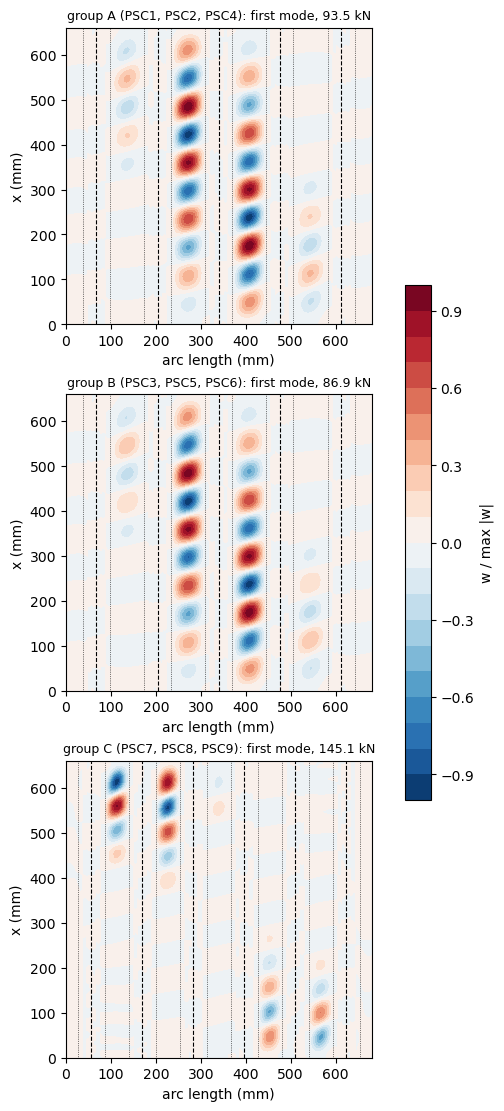

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(8, 11), constrained_layout=True)
for axis, g in zip(axes, GROUPS):
    res = conv[(g, M_FIN, N_FIN)]
    X, S, W = pu.skin_field(res['parts']['skins'], res['evec'][:, 0], gridx=100)
    W = W/np.abs(W).max()
    cs = axis.contourf(S, X, W, levels=np.linspace(-1, 1, 21), cmap='RdBu_r')
    for ys in GROUPS[g]['ys']:
        axis.axvline(ys, color='k', lw=0.8, ls='--')
        for dy in (-30., 30.):
            axis.axvline(ys + dy, color='k', lw=0.5, ls=':')
    axis.set_aspect('equal')
    axis.set_xlabel('arc length (mm)')
    axis.set_ylabel('x (mm)')
    axis.set_title('group %s (%s): first mode, %.1f kN'
                   % (g, GROUPS[g]['panels'], res['crit']), fontsize=9)
fig.colorbar(cs, ax=axes, shrink=0.5, label='w / max |w|')
plt.show()

## 7. Sensitivity

With the mesh $m = 24$, $n = 12$ of Section 4, for group A:

* the unloaded edges clamped ($w = w_{,y} = 0$) instead of $w = 0$;
* the length 680 mm, the "nominal test length" of [1] (p. 1189), instead of the 660 mm between the
  end loading pieces of the drawing of [2];
* the feet removed, the blades standing on the skin (the blade domain is then measured from the
  mid-surface of the skin, and the widest bay, 136 mm, has $n = 24$), which shows how much the feet
  stiffen the skin.

In [7]:
M_S, N_S = 24, 12
base = conv[('A', M_S, N_S)]['crit']
# without feet the widest bay is 136 mm instead of 76 mm: more terms across it
cases = [('unloaded edges clamped', N_S, dict(unloaded='clamped')),
         ('length 680 mm', N_S, dict(L=680.)),
         ('no feet', 24, dict(feet=[]))]
rows = [['model of Sections 2 to 5', '%.1f' % base, '']]
for name, n, kwargs in cases:
    res = solve('A', M_S, n, **kwargs)
    rows.append([name, '%.1f' % res['crit'], '%+.1f' % rel(res['crit'], base)])
print_table(rows, ['group A, m = %d, n = %d' % (M_S, N_S), 'first buckling (kN)', 'change %'])

 group A, m = 24, n = 12  first buckling (kN)  change %
------------------------  -------------------  --------
model of Sections 2 to 5                 93.5          
  unloaded edges clamped                 93.5      +0.0
           length 680 mm                 93.6      +0.1
                 no feet                 49.8     -46.7


## 8. Discussion

**Convergence.** The first buckling load of the three groups changes by less than 0.1 % from $m = 24$
to $m = 28$, and by 0.01 % or less with more terms across the feet and the blades (Section 4). The
warnings printed during the convergence study come from the null-space elimination of the connections:
the gap between the smallest independent pivot of the constraints (6.9e-6) and the largest redundant
one (8.7e-10) is narrower than usual but still of more than three orders of magnitude, and the loads of
all meshes follow the same convergence.

**Finite element model of [2].** The loads of the plate-assembly model agree with the MSC/NASTRAN first
buckling loads of [2] within -2.4 % (group B) to +4.4 % (group C). Both are linear analyses of the
perfect panels with the nominal data; [2] does not describe its mesh, its boundary conditions or its
model of the feet, and the plies of the foot steps are assumed here, so the remaining differences are
not resolved further. Both models give the same trends: the 15 mm blades lower the load, by 3 % in [2]
and 7 % here, and the sixth blade raises it, by 51 % in [2] and 55 % here.

**Tests.** Both linear analyses are well below the first buckling loads measured on the panels, this
model by 23 % to 41 %, as [2] notes for its own predictions ("the predicted local buckling loads under-estimated the test
results", p. 2), and the three nominally identical panels of each group differ by up to 21 % (group A:
131.0 to 158.5 kN). The test value is the load at which the first buckle is seen with the Moiré
technique or in the strain gauges ([1], p. 1189; [2], p. 2), which is not the bifurcation load of a
perfect panel; neither [1] nor [2] explains the difference, and the model does not either.

**Mode shapes and sensitivity.** The first mode is a buckling of the skin in the bays between the feet,
with about ten half-waves along the length in the two central bays of groups A and B, and near the
loaded edges in the bays of group C. Accordingly, the support of the unloaded edges and the length, 660
or 680 mm, change the load by 0.1 % or less (Section 7). The feet, on the contrary, decide the load:
without them the bays are 136 mm wide instead of 76 mm and the load drops by 47 %. The ply drops of the
feet, which are assumed (Section 1), are therefore the main open datum of this model.


In [8]:
print('total run time: %.0f min' % ((time.time() - T_START)/60))

total run time: 32 min
